# Long-horizon industrial digital-twin analysis

This notebook plans a three-product pasta factory over **24 months**. Quantities are tonnes per month, so the model is deliberately aggregate: it is suitable for sales-and-operations planning rather than daily machine sequencing. We use the twin to turn a production plan into inventory, deliveries, shortages, energy use, and cost; then we test a disruption and outline ways to optimise the plan.

## Process

1. Define forecast demand, starting stock, line capacity, process energy, and monthly electricity prices.
2. Simulate a feasible reference plan that deliberately builds stock in lower-price months.
3. Read the operational outputs: stock, service level, capacity, and energy/cost.
4. Re-run the same plan under a demand shock to quantify resilience.
5. Use the resulting model as the basis for an optimisation formulation.

In [1]:
from dataclasses import replace
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import torch

project_root = Path.cwd()
if not (project_root / 'modules').exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from modules.digital_twin import FactoryDigitalTwin, FactoryParameters

month_labels = [f'{year}-{month:02d}' for year in (2026, 2027) for month in range(1, 13)]
product_labels = ['Penne', 'Fusilli', 'Whole-wheat']

# Named tensors document both the business meaning and the expected axes.
seasonal_demand_factor_by_month = torch.tensor(
    [0.92, 0.90, 0.96, 1.00, 1.04, 1.08, 1.12, 1.10, 1.03, 0.98, 1.06, 1.20,
     0.94, 0.91, 0.97, 1.01, 1.05, 1.09, 1.13, 1.11, 1.04, 0.99, 1.07, 1.22], dtype=torch.float64
)
average_monthly_demand_tonnes_by_product = torch.tensor([2500.0, 1800.0, 950.0], dtype=torch.float64)
demand_tonnes_by_month_and_product = torch.outer(
    seasonal_demand_factor_by_month, average_monthly_demand_tonnes_by_product
).round()
initial_inventory_tonnes_by_product = torch.tensor([3500.0, 2200.0, 1200.0], dtype=torch.float64)
monthly_capacity_tonnes_per_line_by_product = torch.tensor([3000.0, 2400.0, 1400.0], dtype=torch.float64)
process_energy_kwh_per_tonne_by_product = torch.tensor([82.0, 96.0, 118.0], dtype=torch.float64)
electricity_tariff_eur_per_kwh_by_month = torch.tensor(
    [0.145, 0.138, 0.132, 0.128, 0.135, 0.151, 0.168, 0.173, 0.162, 0.149, 0.156, 0.181,
     0.152, 0.143, 0.136, 0.131, 0.139, 0.157, 0.176, 0.182, 0.169, 0.154, 0.162, 0.188], dtype=torch.float64
)

parameters = FactoryParameters(
    demand=demand_tonnes_by_month_and_product,
    initial_inventory=initial_inventory_tonnes_by_product,
    production_capacity=monthly_capacity_tonnes_per_line_by_product,
    process_energy_per_unit=process_energy_kwh_per_tonne_by_product,
    tariff=electricity_tariff_eur_per_kwh_by_month,
    lines=3,
    base_load_kwh=42000.0,
    activation_kwh=8000.0,
    failure_penalty=900.0,
)
twin = FactoryDigitalTwin(parameters)

named_input_tensors = {
    'Demand (tonnes: month × product)': demand_tonnes_by_month_and_product,
    'Initial inventory (tonnes: product)': initial_inventory_tonnes_by_product,
    'Capacity (tonnes / line-month: product)': monthly_capacity_tonnes_per_line_by_product,
    'Process energy (kWh / tonne: product)': process_energy_kwh_per_tonne_by_product,
    'Electricity tariff (EUR / kWh: month)': electricity_tariff_eur_per_kwh_by_month,
}
named_input_tensors

{'Demand (tonnes: month × product)': tensor([[2300., 1656.,  874.],
         [2250., 1620.,  855.],
         [2400., 1728.,  912.],
         [2500., 1800.,  950.],
         [2600., 1872.,  988.],
         [2700., 1944., 1026.],
         [2800., 2016., 1064.],
         [2750., 1980., 1045.],
         [2575., 1854.,  978.],
         [2450., 1764.,  931.],
         [2650., 1908., 1007.],
         [3000., 2160., 1140.],
         [2350., 1692.,  893.],
         [2275., 1638.,  864.],
         [2425., 1746.,  922.],
         [2525., 1818.,  960.],
         [2625., 1890.,  998.],
         [2725., 1962., 1036.],
         [2825., 2034., 1074.],
         [2775., 1998., 1054.],
         [2600., 1872.,  988.],
         [2475., 1782.,  940.],
         [2675., 1926., 1017.],
         [3050., 2196., 1159.]], dtype=torch.float64),
 'Initial inventory (tonnes: product)': tensor([3500., 2200., 1200.], dtype=torch.float64),
 'Capacity (tonnes / line-month: product)': tensor([3000., 2400., 1400.], dtype=t

## 1. Inspect the planning assumptions

Demand combines product mix with seasonal growth, including a realistic year-end peak. Electricity is more expensive in summer and winter. Capacity is expressed per line-month; the sum of each product's planned fraction of a line cannot exceed the factory's three available lines.

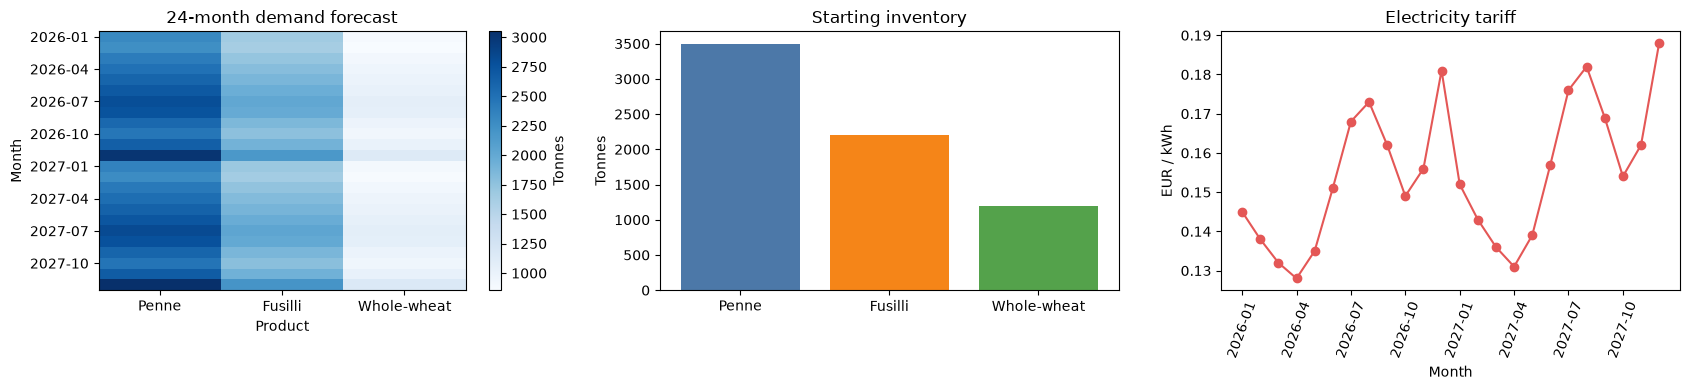

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
image = axes[0].imshow(demand_tonnes_by_month_and_product.numpy(), cmap='Blues', aspect='auto')
axes[0].set(title='24-month demand forecast', xlabel='Product', ylabel='Month',
            xticks=range(twin.products), xticklabels=product_labels,
            yticks=range(0, twin.horizon, 3), yticklabels=month_labels[::3])
fig.colorbar(image, ax=axes[0], label='Tonnes')
axes[1].bar(product_labels, initial_inventory_tonnes_by_product.numpy(), color=['#4C78A8', '#F58518', '#54A24B'])
axes[1].set(title='Starting inventory', ylabel='Tonnes')
axes[2].plot(month_labels, electricity_tariff_eur_per_kwh_by_month.numpy(), marker='o', color='#E45756')
axes[2].set(title='Electricity tariff', ylabel='EUR / kWh', xlabel='Month')
axes[2].tick_params(axis='x', rotation=70)
axes[2].set_xticks(range(0, twin.horizon, 3), month_labels[::3])
fig.tight_layout()
plt.show()

## 2. Simulate a reference production plan

The reference plan produces the forecast need plus a modest stock-building amount in the lowest-tariff months. It is intentionally a transparent business rule, not an optimum. This is useful as a baseline against which an optimiser can later demonstrate improvement.

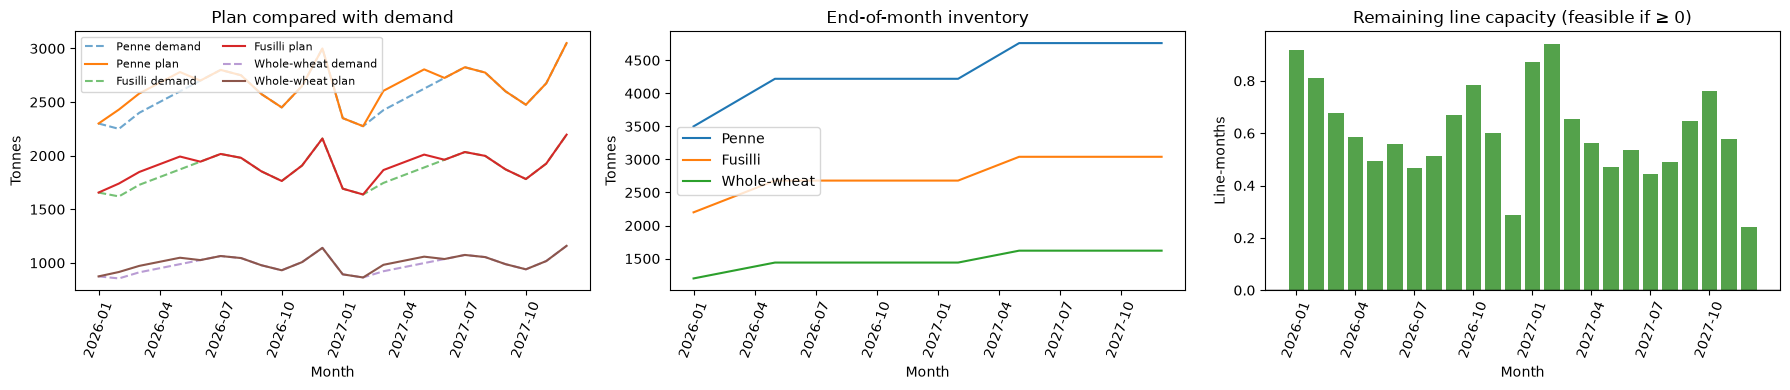

Delivery success rate: 100.0%
Remaining capacity range: 0.24 to 0.94 line-months


In [8]:
low_tariff_month_mask = electricity_tariff_eur_per_kwh_by_month <= 0.140
stock_build_tonnes_by_product = torch.tensor([180.0, 120.0, 60.0], dtype=torch.float64)
planned_production_tonnes_by_month_and_product = (
    demand_tonnes_by_month_and_product
    + low_tariff_month_mask.unsqueeze(1) * stock_build_tonnes_by_product
).clone().detach().requires_grad_(True)
baseline_result = twin.simulate(planned_production_tonnes_by_month_and_product)
remaining_line_capacity_by_month = twin.capacity_constraints(planned_production_tonnes_by_month_and_product).detach()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for product_index, product_name in enumerate(product_labels):
    axes[0].plot(month_labels, demand_tonnes_by_month_and_product.numpy()[:, product_index], linestyle='--', alpha=0.65, label=f'{product_name} demand')
    axes[0].plot(month_labels, planned_production_tonnes_by_month_and_product.detach().numpy()[:, product_index], label=f'{product_name} plan')
    axes[1].plot(month_labels, baseline_result.inventory.detach().numpy()[:, product_index], label=product_name)
axes[0].set(title='Plan compared with demand', ylabel='Tonnes', xlabel='Month')
axes[1].set(title='End-of-month inventory', ylabel='Tonnes', xlabel='Month')
axes[2].bar(month_labels, remaining_line_capacity_by_month.numpy(), color='#54A24B')
axes[2].axhline(0, color='black', linewidth=1)
axes[2].set(title='Remaining line capacity (feasible if ≥ 0)', ylabel='Line-months', xlabel='Month')
for axis in axes:
    axis.set_xticks(range(0, twin.horizon, 3), month_labels[::3])
    axis.tick_params(axis='x', rotation=70)
axes[0].legend(ncol=2, fontsize=8)
axes[1].legend()
fig.tight_layout()
plt.show()

print(f'Delivery success rate: {baseline_result.delivery_success_rate.item():.1%}')
print(f'Remaining capacity range: {remaining_line_capacity_by_month.min().item():.2f} to {remaining_line_capacity_by_month.max().item():.2f} line-months')

## 3. Measure economic and service performance

The twin separates the electricity bill from the penalty for unmet tonnes. The shortage heat map also shows *where* service fails, which is often more actionable than an aggregate service percentage.

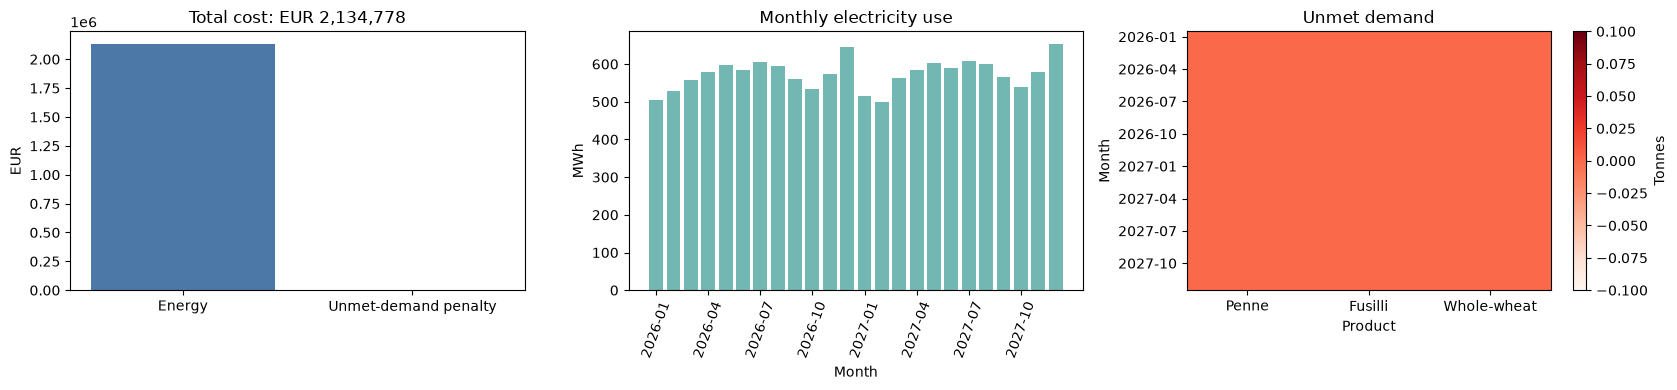

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].bar(['Energy', 'Unmet-demand penalty'], [baseline_result.energy_cost.item(), baseline_result.failure_cost.item()], color=['#4C78A8', '#E45756'])
axes[0].set(title=f'Total cost: EUR {baseline_result.total_cost.item():,.0f}', ylabel='EUR')
axes[1].bar(month_labels, baseline_result.energy_kwh.detach().numpy() / 1000, color='#72B7B2')
axes[1].set(title='Monthly electricity use', ylabel='MWh', xlabel='Month')
shortage_image = axes[2].imshow(baseline_result.unmet_demand.detach().numpy(), cmap='Reds', aspect='auto')
axes[2].set(title='Unmet demand', xlabel='Product', ylabel='Month',
            xticks=range(twin.products), xticklabels=product_labels,
            yticks=range(0, twin.horizon, 3), yticklabels=month_labels[::3])
fig.colorbar(shortage_image, ax=axes[2], label='Tonnes')
axes[1].set_xticks(range(0, twin.horizon, 3), month_labels[::3])
axes[1].tick_params(axis='x', rotation=70)
fig.tight_layout()
plt.show()

## 4. Test resilience with a demand shock

For the final six months, the scenario below increases demand by 35% to represent a sustained customer win or severe forecast error. No production decision is changed: this isolates the exposure of the reference plan.

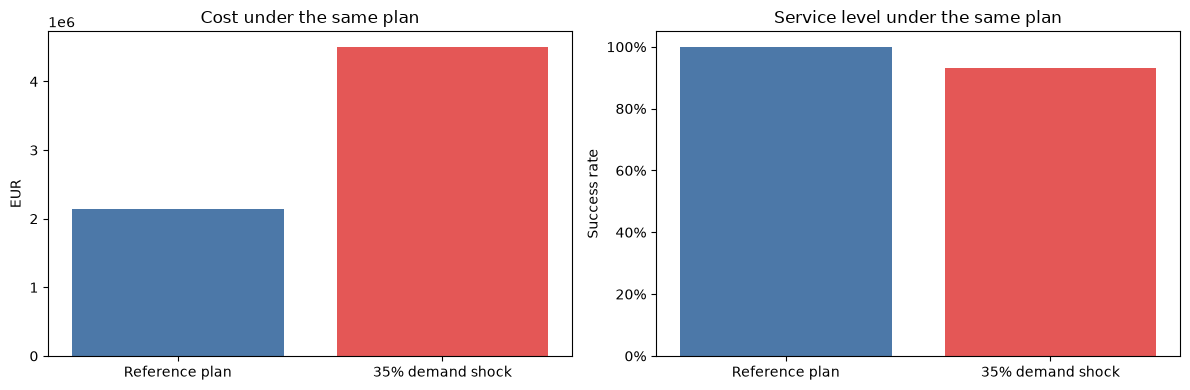

Additional unmet demand in the shock: 2,634 tonnes


In [7]:
shock_demand_tonnes_by_month_and_product = demand_tonnes_by_month_and_product.clone()
shock_demand_tonnes_by_month_and_product[18:24] *= 1.35
shock_twin = FactoryDigitalTwin(replace(parameters, demand=shock_demand_tonnes_by_month_and_product))
shock_result = shock_twin.simulate(planned_production_tonnes_by_month_and_product.detach())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
scenario_labels = ['Reference plan', '35% demand shock']
axes[0].bar(scenario_labels, [baseline_result.total_cost.item(), shock_result.total_cost.item()], color=['#4C78A8', '#E45756'])
axes[0].set(title='Cost under the same plan', ylabel='EUR')
axes[1].bar(scenario_labels, [baseline_result.delivery_success_rate.item(), shock_result.delivery_success_rate.item()], color=['#4C78A8', '#E45756'])
axes[1].set(title='Service level under the same plan', ylabel='Success rate', ylim=(0, 1.05))
axes[1].yaxis.set_major_formatter('{x:.0%}')
fig.tight_layout()
plt.show()

print(f'Additional unmet demand in the shock: {(shock_result.unmet_demand.sum() - baseline_result.unmet_demand.sum()).item():,.0f} tonnes')

## 5. Sensitivity: where an extra tonne matters

The model is differentiable. The heat map is the change in the penalised objective for one additional tonne in each product-month. Negative values identify places where additional production would reduce shortage penalties enough to outweigh energy and capacity effects.

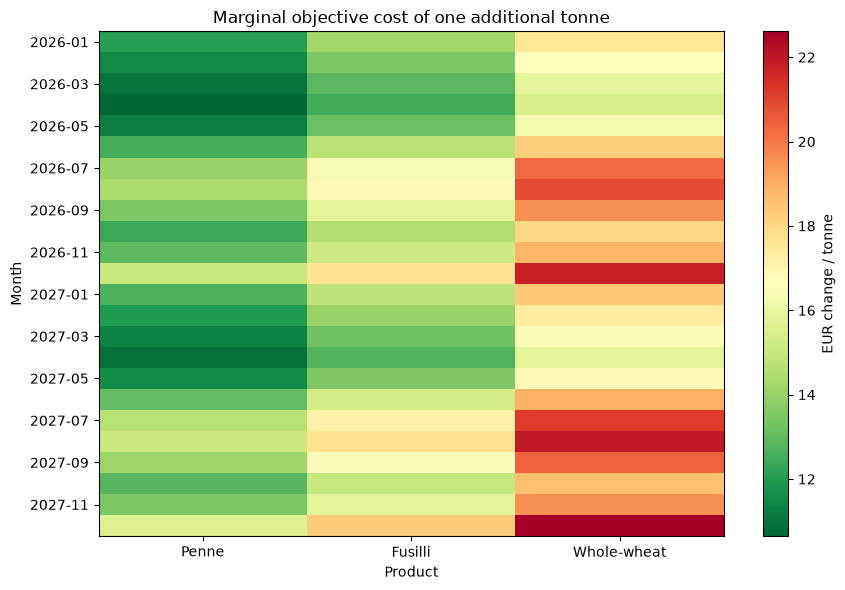

In [6]:
penalised_objective = twin.objective(planned_production_tonnes_by_month_and_product, capacity_penalty=1_000_000.0)
penalised_objective.backward()
marginal_cost_eur_per_tonne_by_month_and_product = planned_production_tonnes_by_month_and_product.grad.detach()

fig, axis = plt.subplots(figsize=(9, 6))
image = axis.imshow(marginal_cost_eur_per_tonne_by_month_and_product.numpy(), cmap='RdYlGn_r', aspect='auto')
axis.set(title='Marginal objective cost of one additional tonne', xlabel='Product', ylabel='Month',
         xticks=range(twin.products), xticklabels=product_labels,
         yticks=range(0, twin.horizon, 2), yticklabels=month_labels[::2])
fig.colorbar(image, ax=axis, label='EUR change / tonne')
fig.tight_layout()
plt.show()

## Perspectives: optimisation formulations

The next step is to choose `x[m, p]`, the production tonnes for month `m` and product `p`, rather than supplying a rule-based plan. Demand `d[m, p]` is the given amount of need; `I[m, p]`, `y[m, p]`, and `u[m, p]` are inventory, delivered tonnes, and unmet tonnes.

**Core operational formulation.** For every month and product, enforce the material balance `I[m,p] = I[m-1,p] + x[m,p] - y[m,p]`, `y[m,p] + u[m,p] = d[m,p]`, and non-negativity. The line constraint is `Σp x[m,p] / capacity[p] ≤ 3`. This guarantees that the plan meets known needs wherever possible while respecting the three-line operation. Add storage limits, minimum campaign sizes, maintenance outages, or safety-stock constraints when those data are available.

**Energy-aware objective.** Minimise `Σm tariff[m] × energy[m] + 900 × Σm,p u[m,p]`, optionally adding inventory holding cost and a smoothing term such as `|x[m,p] - x[m-1,p]|`. The twin's energy equation includes base load, product-specific kWh per tonne, and smooth line activation. It directly supports differentiable, penalty-based optimisation through `twin.objective(...)`.

**Solver choices.** A linear programme is appropriate if energy is approximated as a fixed plus per-tonne cost. A mixed-integer linear programme adds binary line, shift, or changeover decisions. A nonlinear differentiable formulation retains the twin's smooth activation curve and can be solved with projected gradient methods or an automatic-differentiation optimiser. In every case, validate the optimised plan by simulating it with this notebook, then stress-test it with demand, tariff, and capacity scenarios.